# Braun et al. (2026), Supp. Fig. 8 — after silencing, sequences reset; the profile sets where (WP0.5)

> Top rows: responses to silencing (100 neurons, 1.7 s) for offsets 0, 0.2, 0.4 (a = 0.6, σ = 1 s), widths 1, 1.5, 2 s
> (a = 0.6, b = 0) and amplitudes 0.6, 0.8, 1 (σ = 1 s, b = 0). Bottom rows: connectivity profile of the same
> network. "The ensemble to which the sequence resets is as far away from the silenced ensemble as the position of
> the minimum in the connectivity profile." At a = 1, parallel transient sequences appear (several minima).

**Panels:** A offset · B width · C amplitude (response + profile per condition) · D (added) measured reset distance
against the profile minimum, all ensembles silenced in their active window, every condition.

Networks: realisation 1 of each condition (dev settings), protocol as in the Fig. 4 notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seqnet.figures import Figure, style
from seqnet.experiments import wp0
from seqnet import conventions as cv
from seqnet.sequences import braun_sequence, logit_target
from seqnet.models.rate_rnn import simulate, RNNParams, Perturbation
from seqnet.analysis import perturb as pt
from seqnet.analysis.profile_features import preprocess_profile

style()
fig = Figure("wp0", "braun_supp8")
c4 = Figure("wp0", "braun_fig4").config(); prm = RNNParams(); dt = prm.dt
rows = {"A_offset": [(0.6, 1.0, 0.0), (0.6, 1.0, 0.2), (0.6, 1.0, 0.4)], "B_width": [(0.6, 1.0, 0.0), (0.6, 1.5, 0.0), (0.6, 2.0, 0.0)],
        "C_amplitude": [(0.6, 1.0, 0.0), (0.8, 1.0, 0.0), (1.0, 1.0, 0.0)]}
ex = c4["example"]; ws, nw, ns = c4["window_steps"], c4["n_windows"], c4["n_steps"]

def analyse(a, s, b):
    run = wp0.get(a, s, b, c4["settings"]); J = run.W(c4["realisation"])
    spec = braun_sequence(amp=a, width=s, offset=b); h0 = logit_target(spec, 0.0)[:, 0]
    ens = pt.ensembles(spec.N, c4["f_E"]); E = ens[ex["ensemble"]]
    r_un = simulate(J, h0, ns, prm, np.random.default_rng(c4["seed"]))["r"]
    w = pt.active_window(r_un, E, ws, nw)
    r = simulate(J, h0, ns, prm, np.random.default_rng(c4["seed"]), perturbations=[Perturbation("silence", E, w * ws, (w + 1) * ws)])["r"]
    d, sm, _ = preprocess_profile(cv.profile_from_matrix(J)); _, raw = cv.centred_profile(cv.profile_from_matrix(J))
    nz = d != 0; d_min = int(d[nz][np.argmin(sm[nz])])
    # alternative predictors: nearest local minimum on each side, and the zero crossings (excitation -> inhibition)
    from scipy.signal import find_peaks
    mins = d[find_peaks(-sm, prominence=0.001)[0]]
    neg_min = int(mins[mins < 0].max()) if np.any(mins < 0) else 0
    pos_min = int(mins[mins > 0].min()) if np.any(mins > 0) else 0
    i0 = int(np.nonzero(d == 0)[0][0])
    left = np.nonzero(sm[:i0] < 0)[0]; right = np.nonzero(sm[i0:] < 0)[0]
    neg_zero = int(d[left.max()]) if left.size else 0
    pos_zero = int(d[i0 + right.min()]) if right.size else 0
    meas = []
    for i, e in enumerate(ens):
        wi = pt.active_window(r_un, e, ws, nw)
        rr = simulate(J, h0, ns, prm, np.random.default_rng(c4["seed"]), perturbations=[Perturbation("silence", e, wi * ws, (wi + 1) * ws)])["r"]
        m_ = rr[(wi + 1) * ws: (wi + 1) * ws + int(0.5 / dt)].mean(0)
        meas.append(((int(np.argmax(m_)) - int(e.mean()) + spec.N // 2) % spec.N) - spec.N // 2)
    return {"r": r[::4].T.astype(np.float32), "E": E, "w": np.array([w * ws, (w + 1) * ws]) * dt, "d": d, "cp_raw": raw, "cp_smooth": sm,
            "d_min": d_min, "measured": np.array(meas), "neg_min": neg_min, "pos_min": pos_min, "neg_zero": neg_zero, "pos_zero": pos_zero}

for row, conds in rows.items():
    for j, (a, s, b) in enumerate(conds):
        fig.save(f"{row}_{j}", params={"amp": a, "width": s, "offset": b}, **analyse(a, s, b))

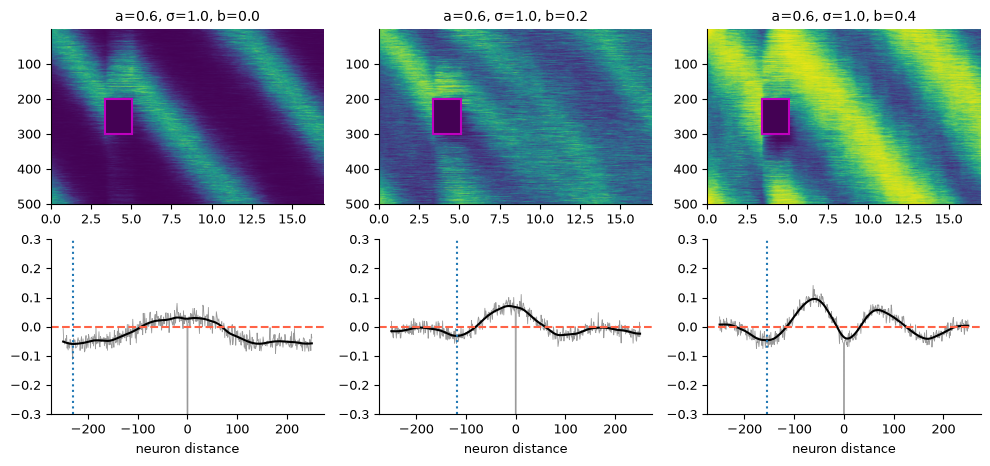

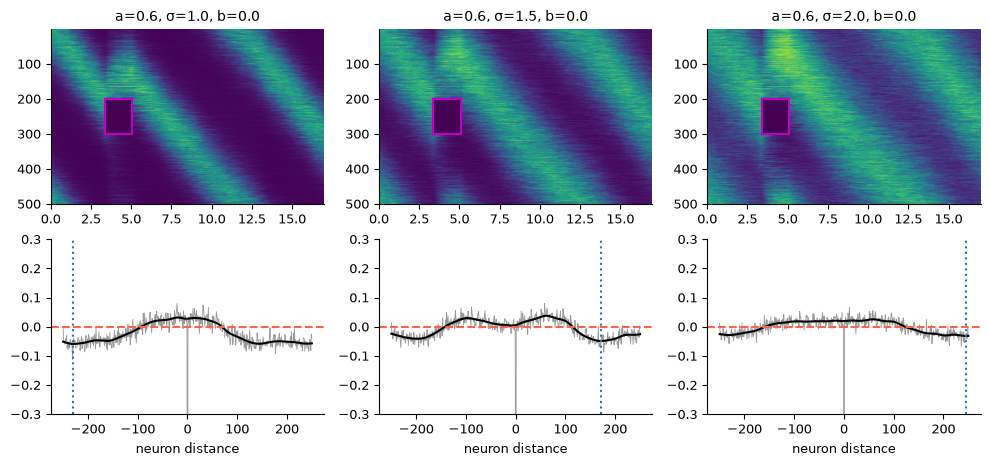

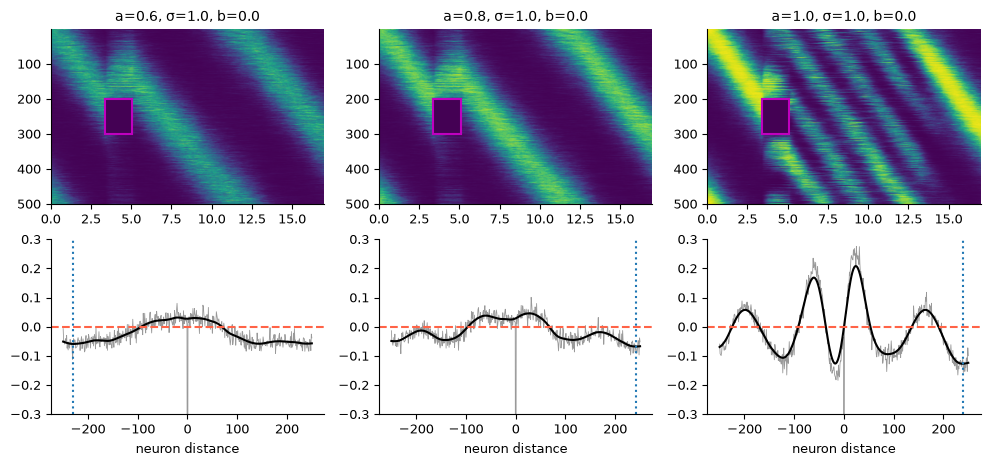

In [2]:
for row, conds in rows.items():
    F, axs = plt.subplots(2, 3, figsize=(12, 5))
    for j, (a, s, b) in enumerate(conds):
        d = fig.load(f"{row}_{j}")
        axs[0, j].imshow(d["r"], aspect="auto", extent=[0, 17, 501, 1], vmin=0, vmax=1)
        axs[0, j].add_patch(plt.Rectangle((d["w"][0], d["E"][0] + 1), d["w"][1] - d["w"][0], len(d["E"]), fill=False, ec="m", lw=1.5))
        axs[0, j].set_title(f"a={a}, σ={s}, b={b}")
        axs[1, j].plot(d["d"], d["cp_raw"], color="0.6", lw=0.6); axs[1, j].plot(d["d"], d["cp_smooth"], "k")
        axs[1, j].axhline(0, color="tomato", ls="--"); axs[1, j].axvline(int(d["d_min"]), color="tab:blue", ls=":")
        axs[1, j].set_ylim(-0.3, 0.3); axs[1, j].set_xlabel("neuron distance")
    fig.savefig(row, F); plt.show()

## Panel D (added) — measured reset distance vs the profile minimum, every ensemble, every condition

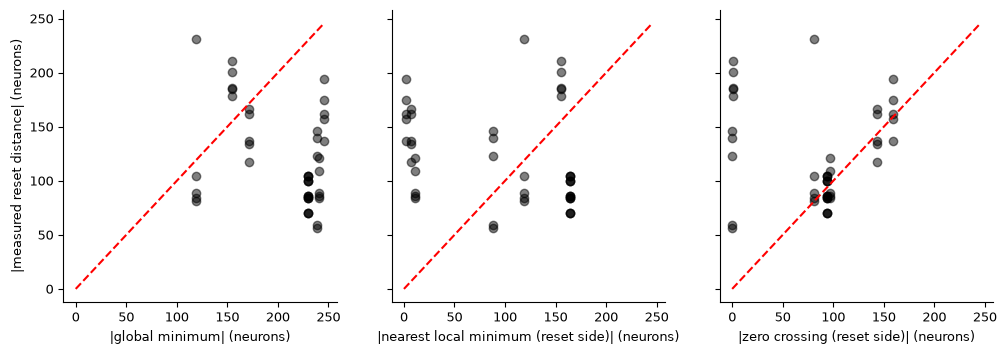

In [3]:
rows_ = []
for row, conds in rows.items():
    for j, _ in enumerate(conds):
        d = fig.load(f"{row}_{j}")
        side = np.sign(np.median(d["measured"])) or -1
        for m_ in d["measured"]:
            rows_.append([m_, int(d["d_min"]), int(d["neg_min"] if side < 0 else d["pos_min"]), int(d["neg_zero"] if side < 0 else d["pos_zero"])])
P = np.array(rows_)
fig.save("D_reset_vs_profile", measured=P[:, 0], global_min=P[:, 1], near_min=P[:, 2], zero_cross=P[:, 3])
F, axs = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, k, lab in zip(axs, [1, 2, 3], ["global minimum", "nearest local minimum (reset side)", "zero crossing (reset side)"]):
    ax.plot(np.abs(P[:, k]), np.abs(P[:, 0]), "ko", alpha=0.5); lim = max(np.abs(P).max(), 10)
    ax.plot([0, lim], [0, lim], "r--"); ax.set_xlabel(f"|{lab}| (neurons)")
axs[0].set_ylabel("|measured reset distance| (neurons)")
fig.savefig("D_reset_vs_profile", F); plt.show()

## Acceptance

In [4]:
d = fig.load("D_reset_vs_profile")
res = {}
for k in ("global_min", "near_min", "zero_cross"):
    err = np.abs(np.abs(d["measured"]) - np.abs(d[k]))
    res[k] = {"median_abs_error": float(np.median(err)), "corr": float(np.corrcoef(np.abs(d["measured"]), np.abs(d[k]))[0, 1]) if np.std(d[k]) > 0 else None}
fig.checks([
    {"item": "reset distance equals the profile-minimum distance (Braun Supp. 8 claim)", "criterion": "median error < 50 neurons for the global or the nearest local minimum",
     "value": res, "passed": bool(min(res["global_min"]["median_abs_error"], res["near_min"]["median_abs_error"]) < 50)},
    {"item": "alternative predictor: zero crossing of the profile", "criterion": "reported", "value": res["zero_cross"], "passed": None},
])

[FAIL] reset distance equals the profile-minimum distance (Braun Supp. 8 claim): {'global_min': {'median_abs_error': 116.0, 'corr': -0.3471591932312398}, 'near_min': {'median_abs_error': 78.0, 'corr': -0.23656224685895624}, 'zero_cross': {'median_abs_error': 13.0, 'corr': -0.05853668617118396}}
[info] alternative predictor: zero crossing of the profile: {'median_abs_error': 13.0, 'corr': -0.05853668617118396}


WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_supp8/acceptance.json')